### Task 4: Set up a routine to compute the lifetime fatigue DEL by integrating the short-term damage predictions from the load surrogate model over the joint distribution of external conditions; the procedure should allow propagating the effects of the uncertainties ($X_M$, $X_W$) to the lifetime DEL. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

InputData = pd.read_excel('ML_ExampleDataSet.xlsx','InputVariables')
InputData = InputData.set_index('Sample_No',drop = False) # Make the "Sample_No" column as index of the data

TargetData = pd.read_excel('ML_ExampleDataSet.xlsx','LoadResults')
TargetData.set_index('PointNo', drop = False, inplace = True) # Make the "PointNo" column as index of the data

AllInputData = InputData.where(InputData['Sample_No']==TargetData['PointNo'])
AllTargetData = TargetData.where(TargetData['PointNo']==InputData['Sample_No'])
AllInputData.drop(columns = 'Sample_No', inplace = True)
AllTargetData.drop(columns = 'PointNo', inplace = True)
AllInputData = AllInputData[["U", "SigmaU", "Alpha"]]
nsamples = AllInputData['U'].count() # Find the total number of data points in the data frame
FeatureNames = AllInputData.columns.values
DependentVariableNames = AllTargetData.columns.values

# Load the provided data sets
wind_data = "HovsoreData_Sonic_100m_2004-2013.csv"
del_data = "ML_ExampleDataSet.xlsx"

# Outfput folder location for generated figures
output_figs = "figures/"
os.makedirs(output_figs, exist_ok=True)

# Read the data into pandas DataFrames
df_wind = pd.read_csv(wind_data)
df_del = pd.read_excel(del_data)

# Clean the data
df_wind = df_wind.dropna(subset=["Wsp","TI"])
df_wind = df_wind[(df_wind['Wsp'] > 0) & (df_wind['Wsp'] < 30) & (df_wind['TI'] > 0) & (df_wind['TI'] < 1)]

In [2]:
# -------------------------------------------------------------------
# Task 1: Joint distribution of input variables
# -------------------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import scipy.optimize as optimize

# Windspeed (U) and turbulence intensity (TI) data
U = df_wind['Wsp'].values
SigmaU = df_wind['TI'].values * U  # Convert TI to standard deviation of wind speed


# === Fit Weibull to u (MLE - Most Likely Estimate) ===
k, _, A = stats.weibull_min.fit(U, floc=0)                  # WEIBULL Distribution fit (floc=0 -> forces the distribution to start at zero)


# === Bin by u, fit Lognormal to sigma_u per bin, then fit a trend curve ===
bins = np.arange(0, 35, 1.0)
centers, means, stds = [], [], []
# lo(wer) and hi(gher) bounds of each bin -> the sigmaU is fitted to the data in that bin
for lo, hi in zip(bins[:-1], bins[1:]):
    s = SigmaU[(U >= lo) & (U < hi)]
    if len(s) < 30:
        continue
    shape, _, scale = stats.lognorm.fit(s, floc=0)          # LOGNORMAL Distribution fit
    centers.append((lo + hi) / 2)
    means.append(scale * np.exp(0.5 * shape**2))
    stds.append(means[-1] * np.sqrt(np.exp(shape**2) - 1))

# Fit a quadratic curve to the mean -> that is what 2 is indicating 
p_mean = np.polyfit(centers, means, 2)
p_std = np.polyfit(centers, stds, 2)
u_max_fit = max(centers)  # clip point to avoid extrapolation blowing up

In [3]:
# -------------------------------------------------------------------
# Task 2: Uncertainty propagation for lifetime DEL
# -------------------------------------------------------------------
import numpy as np
from scipy import stats

def bootstrap_xw(U, block_days=None, Nbootstrap=5000, measurement_cov=0.01, joint_fit_cov=0.01, seed=1):
    rng = np.random.default_rng(seed)
    baseline_mean_u = np.mean(U)
    N = len(U)
    BootstrapMeans = np.empty(Nbootstrap)

    # IID bootstrap (no block structure)
    if block_days is None:
        for i in range(Nbootstrap):
            bootstrap_sample = rng.choice(U, size=N, replace=True)
            measurement_factor = (1.0 + rng.normal(0, measurement_cov))
            BootstrapMeans[i] = (np.mean(bootstrap_sample) * measurement_factor)

    # Block bootstrap
    else:
        block_size = int(block_days * 144) # 144 records/day
        for i in range(Nbootstrap):
            bootstrap_series = []
            while len(bootstrap_series) < N:
                start = rng.integers(0, N)
                idx = (np.arange(start, start + block_size) % N)
                bootstrap_series.extend(U[idx])
            bootstrap_series = np.asarray(bootstrap_series[:N])
            measurement_factor = (1.0 + rng.normal(0, measurement_cov))
            BootstrapMeans[i] = (np.mean(bootstrap_series)* measurement_factor)
    Xw_bootstrap = BootstrapMeans / baseline_mean_u
    joint_fit_factor = (1.0 + rng.normal(0, joint_fit_cov, Nbootstrap))
    Xw = Xw_bootstrap * joint_fit_factor

    return Xw[Xw > 0]

Xw_365d = bootstrap_xw(U, block_days=365)

In [7]:
# -------------------------------------------------------------------
# Task 3: ML Model for short-term load prediction
# -------------------------------------------------------------------
import sklearn
import sklearn.neural_network
from sklearn.utils import resample
from sklearn.neural_network import MLPRegressor


InputData = pd.read_excel('ML_ExampleDataSet.xlsx', 'InputVariables')
InputData = InputData.set_index('Sample_No', drop=False)

TargetData = pd.read_excel('ML_ExampleDataSet.xlsx', 'LoadResults')
TargetData.set_index('PointNo', drop=False, inplace=True)

AllInputData = InputData.where(InputData['Sample_No'] == TargetData['PointNo']).copy()
AllTargetData = TargetData.where(TargetData['PointNo'] == InputData['Sample_No']).copy()
AllInputData = AllInputData.drop(columns=['Sample_No']).copy()
AllTargetData = AllTargetData.drop(columns=['PointNo']).copy()
AllInputData = AllInputData[["U", "SigmaU", "Alpha"]].copy()

N_models = 50
ANN_models = []

# Fit the scalers once using all available training data
Xscaler = sklearn.preprocessing.StandardScaler().fit(AllInputData.values)
Yscaler = sklearn.preprocessing.StandardScaler().fit(
    AllTargetData["Blade_root_flapwise_M_x"].values.reshape(-1, 1)
)

X_all = Xscaler.transform(AllInputData.values)
Y_all = Yscaler.transform(
    AllTargetData["Blade_root_flapwise_M_x"].values.reshape(-1, 1)
).ravel()

for model_number in range(N_models):
    X_boot, Y_boot = resample(
        X_all,
        Y_all,
        replace=True,
        n_samples=len(X_all),
        random_state=model_number,
    )

    model = MLPRegressor(
        activation="tanh",
        hidden_layer_sizes=(8, 8),
        max_iter=5000,
        random_state=model_number,
    )

    model.fit(X_boot, Y_boot)
    ANN_models.append(model)


In [8]:
# -------------------------------------------------------------------
# Task 4: Lifetime DEL calculation
# -------------------------------------------------------------------

# Define the number of iterations
N_outer = 500
N_inner = 10000

m = 10
n_ref = 600
N_life = 20 * 365 * 24 * 6

LifetimeDELs = []

for i in range(N_outer):

    # === OUTER LOOP - Sample climate uncertainty from Task 2 ===
    Xw = np.random.choice(Xw_365d)

    # === INNER LOOP - Sample environmental conditions from Task 1 ===
    # Sample surrogate-model uncertainty
    ANN_i = np.random.choice(ANN_models)

    # Wind speed: propagate the sampled climate factor before building
    # the ANN input variables.
    U_base_MC = stats.weibull_min.rvs(c=k, scale=A, size=N_inner)
    U_MC = Xw * U_base_MC
    U_clip = np.minimum(U_MC, u_max_fit)

    # Conditional SigmaU distribution at the Xw-adjusted wind speed
    sigma_mean = np.polyval(p_mean, U_clip)
    sigma_std = np.polyval(p_std, U_clip)
    SigmaU_MC = np.random.normal(sigma_mean, sigma_std)
    SigmaU_MC = np.maximum(SigmaU_MC, 0.01)         # Avoid negative values

    # Wind shear conditioned on the Xw-adjusted wind speed
    Alpha_MC = np.random.normal(loc=0.1, scale=np.minimum(1.0, 1.0/U_MC))

    # The ANN was trained on [U, SigmaU, Alpha]. Xw is propagated
    # through U_MC and the conditional features derived from it.
    X_MC = np.column_stack([U_MC, SigmaU_MC, Alpha_MC])

    # === ML prediction from Task 3 ===
    X_MC_scaled = Xscaler.transform(X_MC)
    Loads_scaled = ANN_i.predict(X_MC_scaled)
    Loads = Yscaler.inverse_transform(Loads_scaled.reshape(-1, 1)).flatten()

    # === Lifetime DEL integration ===
    Loads = np.maximum(Loads, 0)        # Loads cannot be negative for DEL calculation
    MeanDamage = np.mean(Loads**m)
    DEL_LT = ((N_life / n_ref) * MeanDamage) ** (1 / m)
    LifetimeDELs.append(DEL_LT)


# Results
LifetimeDELs = np.array(LifetimeDELs)

print("Mean lifetime DEL =", np.mean(LifetimeDELs))
print("Standard deviation =", np.std(LifetimeDELs))

print(
    "95% confidence interval =",
    np.percentile(LifetimeDELs, 2.5),
    np.percentile(LifetimeDELs, 97.5))

Mean lifetime DEL = 24646.90996704389
Standard deviation = 596.5505461827631
95% confidence interval = 23609.42073499193 25848.26605422574


Text(0.5, 1.0, 'Lifetime DEL Distribution')

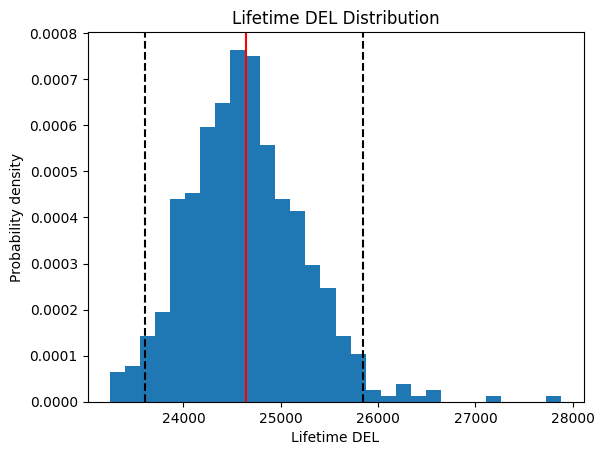

In [9]:
plt.hist(LifetimeDELs,
         bins=30,
         density=True)

plt.xlabel("Lifetime DEL")
plt.ylabel("Probability density")

plt.axvline(np.mean(LifetimeDELs),
            color='red',
            label='Mean')

plt.axvline(np.percentile(LifetimeDELs,2.5),
            color='black',
            linestyle='--')

plt.axvline(np.percentile(LifetimeDELs,97.5),
            color='black',
            linestyle='--')
plt.title("Lifetime DEL Distribution")

for outer_loop:

    # Task 2
    sample Xw

    # Task 1
    sample U, TI, Alpha

    # apply climate uncertainty
    U = Xw * U

    # Task 3
    Loads = ANNmodel.predict(...)

    # fatigue integration
    Damage = np.mean(Loads**m)

    LifetimeDEL = (
        N_life/600 * Damage
    )**(1/m)

    store(LifetimeDEL)